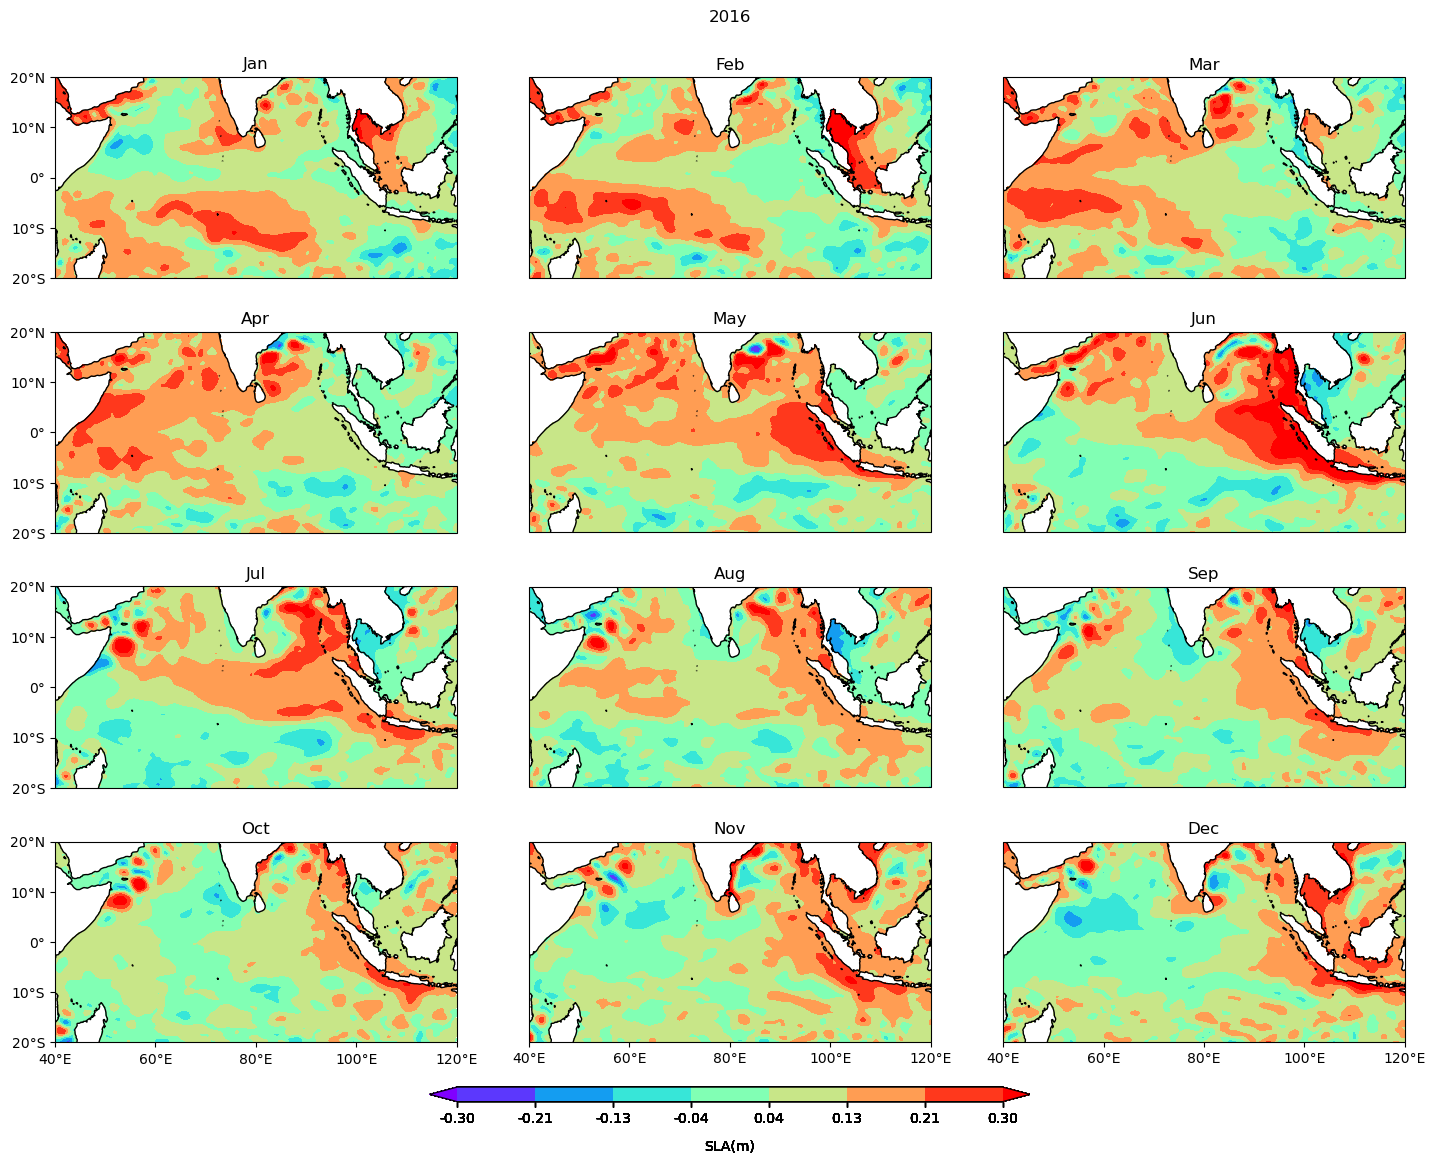

In [23]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import xarray as xr
ds=xr.open_dataset('sla2.nc')
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.mpl.ticker as cticker
import cartopy.feature as cfeature
import calendar
#print(ds)
#open netcdf file
#get data sliced for the particular year
ds = ds.sel(time= slice('1994','2021'),latitude=slice(-20,20),longitude=slice(40,120))
sla=ds['sla']
sla_min=sla.min().values
sla_max=sla.max().values
#print(sla_min)
#print(sla_max)
fig,axs = plt.subplots(nrows = 4, ncols = 3, subplot_kw = {'projection':ccrs.PlateCarree()}, figsize = (15,12))
axs = axs.flatten()

y =22

for i in range(12):
    
    cf = axs[i].contourf(ds['longitude'], ds['latitude'], sla[12*y+i], cmap = 'rainbow',levels = np.linspace(-0.3,0.3,8), extend = 'both')
    axs[i].coastlines()
    axs[i].set_title(calendar.month_abbr[i+1])
    # Add country boundaries
    #axs[i].add_feature(cfeature.BORDERS, edgecolor='black')
    
    # Define the xticks for longitude
    if i >=9:
        lon_range = np.arange(np.floor(ds['longitude'].min()), np.ceil(ds['longitude'].max()) + 1,20)
        axs[i].set_xticks(lon_range, crs=ccrs.PlateCarree())
        lon_formatter = cticker.LongitudeFormatter()
        axs[i].xaxis.set_major_formatter(lon_formatter)
    # Define the yticks for latitude
    if i%3==0:
       lat_range = np.arange(np.floor(ds['latitude'].min()), np.ceil(ds['latitude'].max()) + 1,10)
       axs[i].set_yticks(lat_range, crs=ccrs.PlateCarree())
       lat_formatter = cticker.LatitudeFormatter()
       axs[i].yaxis.set_major_formatter(lat_formatter)
    cbar_ax = fig.add_axes([0.3, 0.07, 0.4, 0.012])
    cbar = fig.colorbar(cf,cax=cbar_ax, orientation='horizontal',label='SLA(m)',format='%.2f')
    cbar.ax.xaxis.set_label_position('bottom')  # Place the label at the top
    cbar.ax.xaxis.set_label_coords(0.5,-2.6)  # Adjust the position of the label
# Adjust the layout to add space between subplots
plt.subplots_adjust(left=0.05, right=0.95, bottom=0.113, top=0.93, wspace=0.18, hspace=0.18)
plt.suptitle(f'{1994+y}')

plt.show()   
   


